0. Add the final HVGs into .var
1. Define Major Features Labels
2. Propagate Major Features throughout dataset
3. Remove cells that remain unlabelled after major features propagation (doublet/crap likely)  
4. Propagate ABC classes
5. Divide into neuronal and glial datasets  


In [1]:
# No need to restart notebook when editing custom packages
%load_ext autoreload
%autoreload 2

In [62]:
from pathlib import Path
import warnings
import tempfile
import os 

warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from dotenv import dotenv_values
sc.set_figure_params(frameon=False, figsize=(10,10), transparent=True)


from hm3d_utils.clustering import propagate_labels_within_dataset
from hm3d_utils.plotting import plot_label_propagation_summary

In [59]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])
CLUSTERING_DIR = DATADIR / "5_clustering"
MODELDIR = CLUSTERING_DIR / 'all_control'
PLOTS_DIR = MODELDIR / 'plots'
HVG_PATH = CLUSTERING_DIR / "clean_control_4500.csv"
CELL_HISTORY = DATADIR / "qc_log.csv" #QC log

### Load and merge datasets

In [4]:
adata = sc.read_h5ad(Path(MODELDIR, 'datasets', 'raw.h5ad'))
embed_only = sc.read_h5ad(Path(MODELDIR, 'datasets', 'embed_only.h5ad'), backed='r')

In [5]:
adata.obsm = embed_only[adata.obs_names].obsm
adata.uns = {k: v for k, v in embed_only.uns.items() if k in {'tsne', 'umap', 'neighbors'}}
adata.obsp = embed_only.obsp

del embed_only
adata

AnnData object with n_obs × n_vars = 924231 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene'
    uns: 'neighbors', 'tsne', 'umap'
    obsm: 'X_embed', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'

### Let's add HVGs into .var 

In [6]:
hvgs = pd.read_csv(HVG_PATH, header=None)
hvgs = hvgs[0].values

In [7]:
adata.var["IsHvg"] = False 
adata.var.loc[hvgs, "IsHvg"] = True

### Let's create 'major_features'

In [ ]:
mapping = {
    '01 IT-ET Glut': 'Glut',
    '03 OB-CR Glut': 'Glut',
    '05 OB-IMN GABA': 'GABA',
    '06 CTX-CGE GABA': 'GABA',
    '07 CTX-MGE GABA': 'GABA',
    '08 CNU-MGE GABA': 'GABA',
    '09 CNU-LGE GABA': 'GABA',
    '10 LSX GABA': 'GABA',
    '11 CNU-HYa GABA': 'GABA',
    '12 HY GABA': 'GABA',
    '13 CNU-HYa Glut': 'Glut',
    '14 HY Glut': 'Glut',
    '15 HY Gnrh1 Glut': 'Glut',
    '16 HY MM Glut': 'Glut',
    '17 MH-LH Glut': 'Glut',
    '18 TH Glut': 'Glut',
    '19 MB Glut': 'Glut',
    '20 MB GABA': 'GABA',
    '21 MB Dopa': 'Dopa',
    '22 MB-HB Sero': 'Sero',
    '23 P Glut': 'Glut',
    '24 MY Glut': 'Glut',
    '25 Pineal Glut': 'Glut',
    '26 P GABA': 'GABA',
    '27 MY GABA': 'GABA',
    '28 CB GABA': 'GABA',
    '30 Astro-Epen': 'Astro-Epen',
    '31 OPC-Oligo': 'OPC-Oligo',
    '33 Vascular': 'Vascular',
    '34 Immune': 'Immune',
    '35 LQ': 'LQ'
}

adata.obs['major_features'] = adata.obs['class_id_label'].map(mapping)

In previous HypoMap3D versions we found a neuronal cluster expressing low levels of Rbfox3 but high levels of markers for VLMCs. 

Additionally, in the UMAP, those cells were forming one visual cluster together with VLMCs, showing strong separation to other clusters. 

In comparison to other cells, these cells also had lower label transfer confidences for major features, suggesting that those cells could have been falsely assigned to neuronal cell types.

Hence, we decided to assign those cells with the "Vascular" major feature.

In [45]:
vlmc_cells = pd.read_csv("resources/vlmc.csv")
vlmc_cells = vlmc_cells.set_index("CellID")

In [46]:
vlmc_cells_in_adata = list(set(vlmc_cells.index).intersection(adata.obs_names))

In [50]:
adata.obs["IsVLMC"] = False 
adata.obs.loc[vlmc_cells_in_adata, "IsVLMC"] = True 
adata.obs.IsVLMC.sum()

np.int64(918)

In [51]:
adata.obs.loc[adata.obs.IsVLMC, 'major_features'] = "Vascular"
adata.obs.drop(columns="IsVLMC", inplace=True)

In [52]:
propagation_label = 'major_features'
propagation_key = 'major_features'

propagate_labels_within_dataset(adata, propagation_label = propagation_label,
    propagation_key = propagation_key)


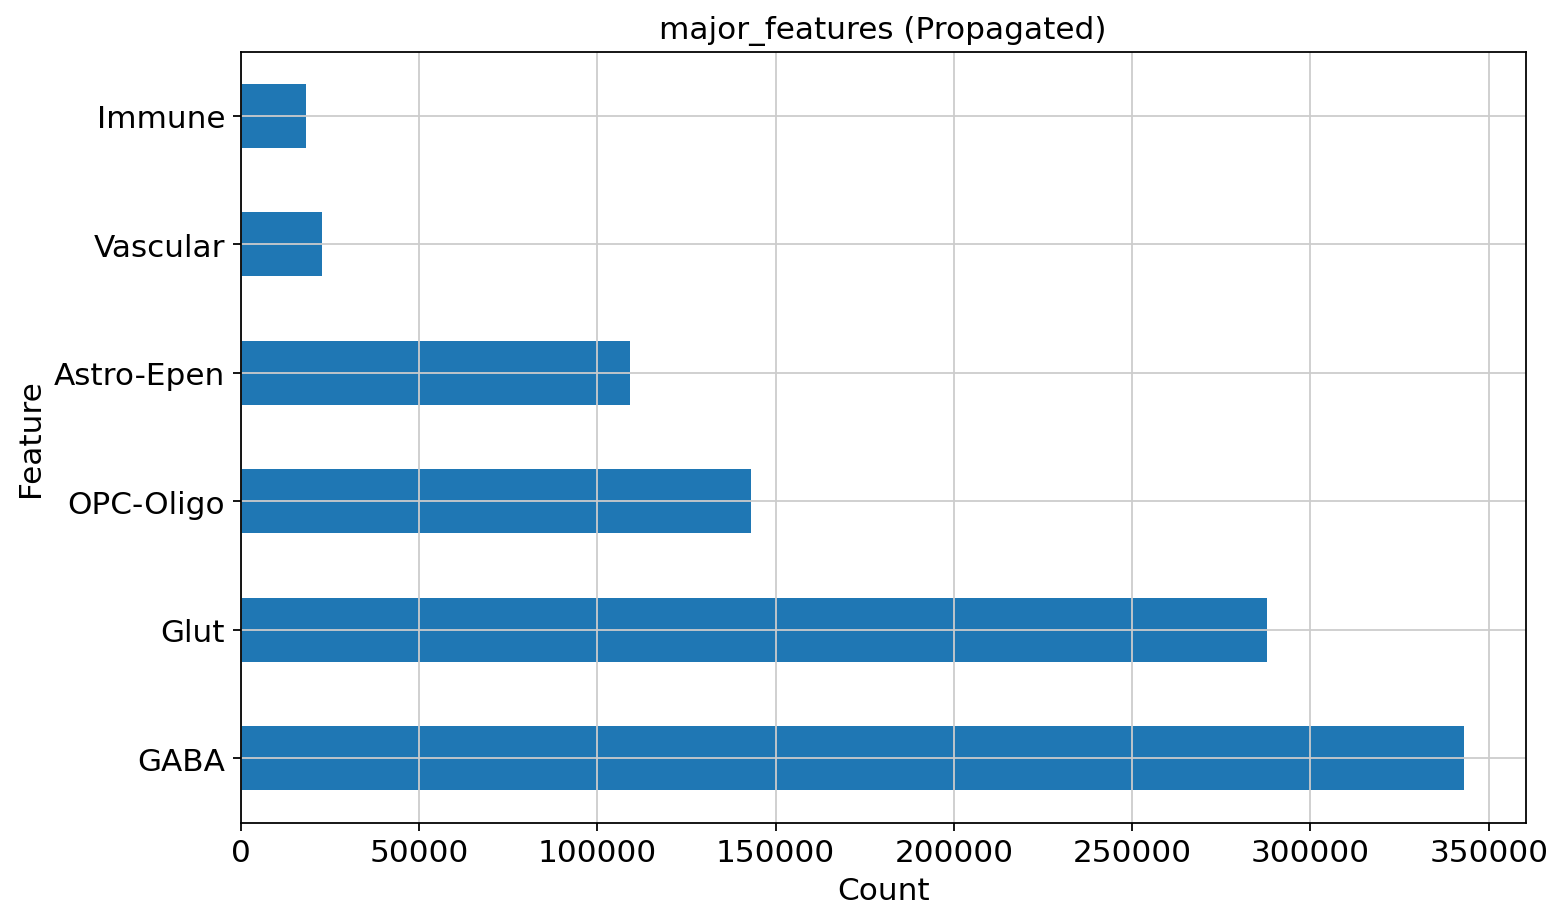

In [53]:
fig, ax = plt.subplots(figsize=(10, 6)) 
adata.obs[f'{propagation_key}_propagated'].value_counts().plot.barh(ax=ax)

ax.set_title(f'{propagation_key} (Propagated)')
ax.set_xlabel('Count')
ax.set_ylabel('Feature')

plt.tight_layout()
plt.savefig(PLOTS_DIR / f'{propagation_key}_propagated_counts.png', dpi=300)  # Save the figure
plt.show()  # Close to free up memory


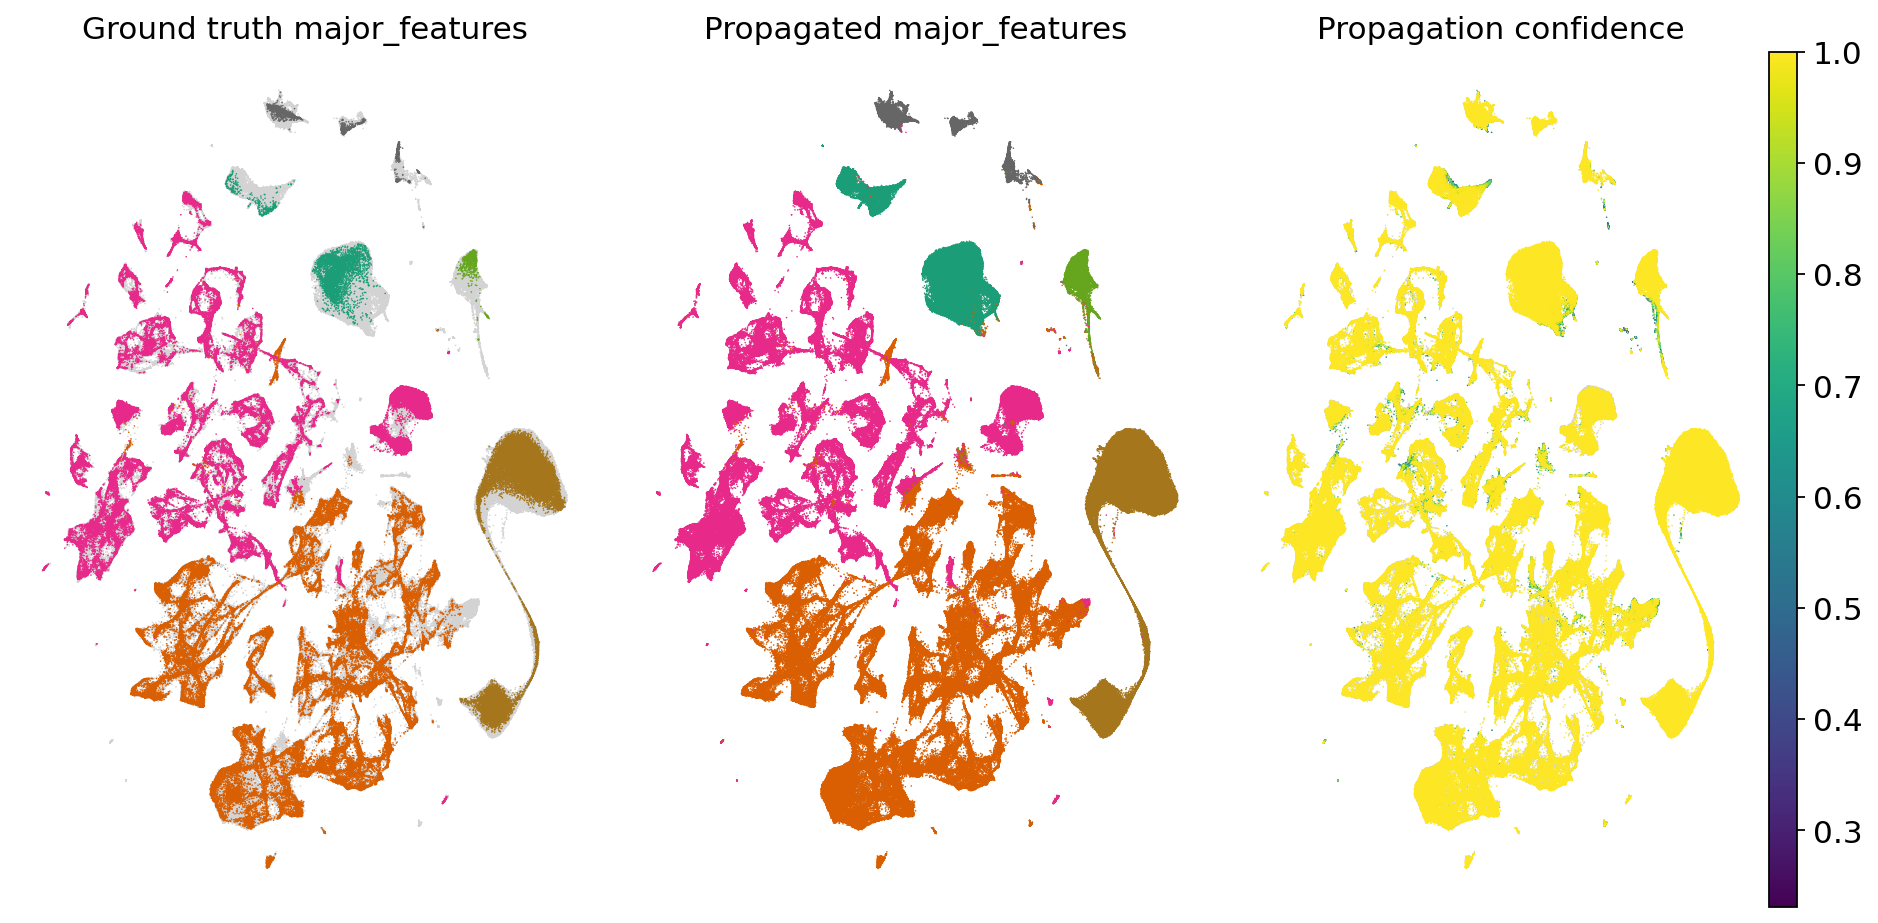

In [54]:
plot_label_propagation_summary(
    adata,
    propagation_label,
    propagation_key,
    save_dir = PLOTS_DIR)

### Remove unlabelled major_feature_propagated

If cells cannot be predicted accurately on such a coarse level they are probably low-quality cells that should be removed

In [55]:
confidence_threshold = 0.5

low_confidence_mask = adata.obs['major_features_confidence'].values < confidence_threshold

# How many are unlabelled?
sum(low_confidence_mask.tolist())

1776

### adding those cells to the QC log

In [63]:
# Load existing file
qc_log_df = pd.read_csv(CELL_HISTORY)

qc_log_df["IsMajorFeatureLowConfidence"] = False
qc_log_df.loc[qc_log_df["CellID"].isin(list(adata[low_confidence_mask, :].obs_names)), "IsMajorFeatureLowConfidence"] = True

# Atomically replace cell history to avoid data corruption
output_path = CELL_HISTORY
output_dir = output_path.parent
# Create temp file in same directory
with tempfile.NamedTemporaryFile(mode="w", delete=False, dir=output_dir, suffix=".csv") as tmp:
    temp_path = Path(tmp.name)
    qc_log_df.to_csv(tmp.name, index=False)

os.replace(temp_path, output_path)

In [64]:
adata = adata[~low_confidence_mask]
adata

View of AnnData object with n_obs × n_vars = 922455 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal', 'major_features', 'major_features_propagated', 'major_features_confidence'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'neighbors', 'tsne', 'umap', 'major_features_colors', 'major_features_propagated_colors'
    obsm: 'X_embed', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'

### Let's propagate 'class_id_label'

In [65]:
propagation_label = 'class_id_label'
propagation_key = 'ABC_class'

propagate_labels_within_dataset(adata, propagation_label = propagation_label,
    propagation_key = propagation_key)


/REDACTED-path/HypoMap3D/src/hm3d_utils/clustering/_query.py:112: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[f'{propagation_key}_propagated'] = adata.obs[propagation_label]


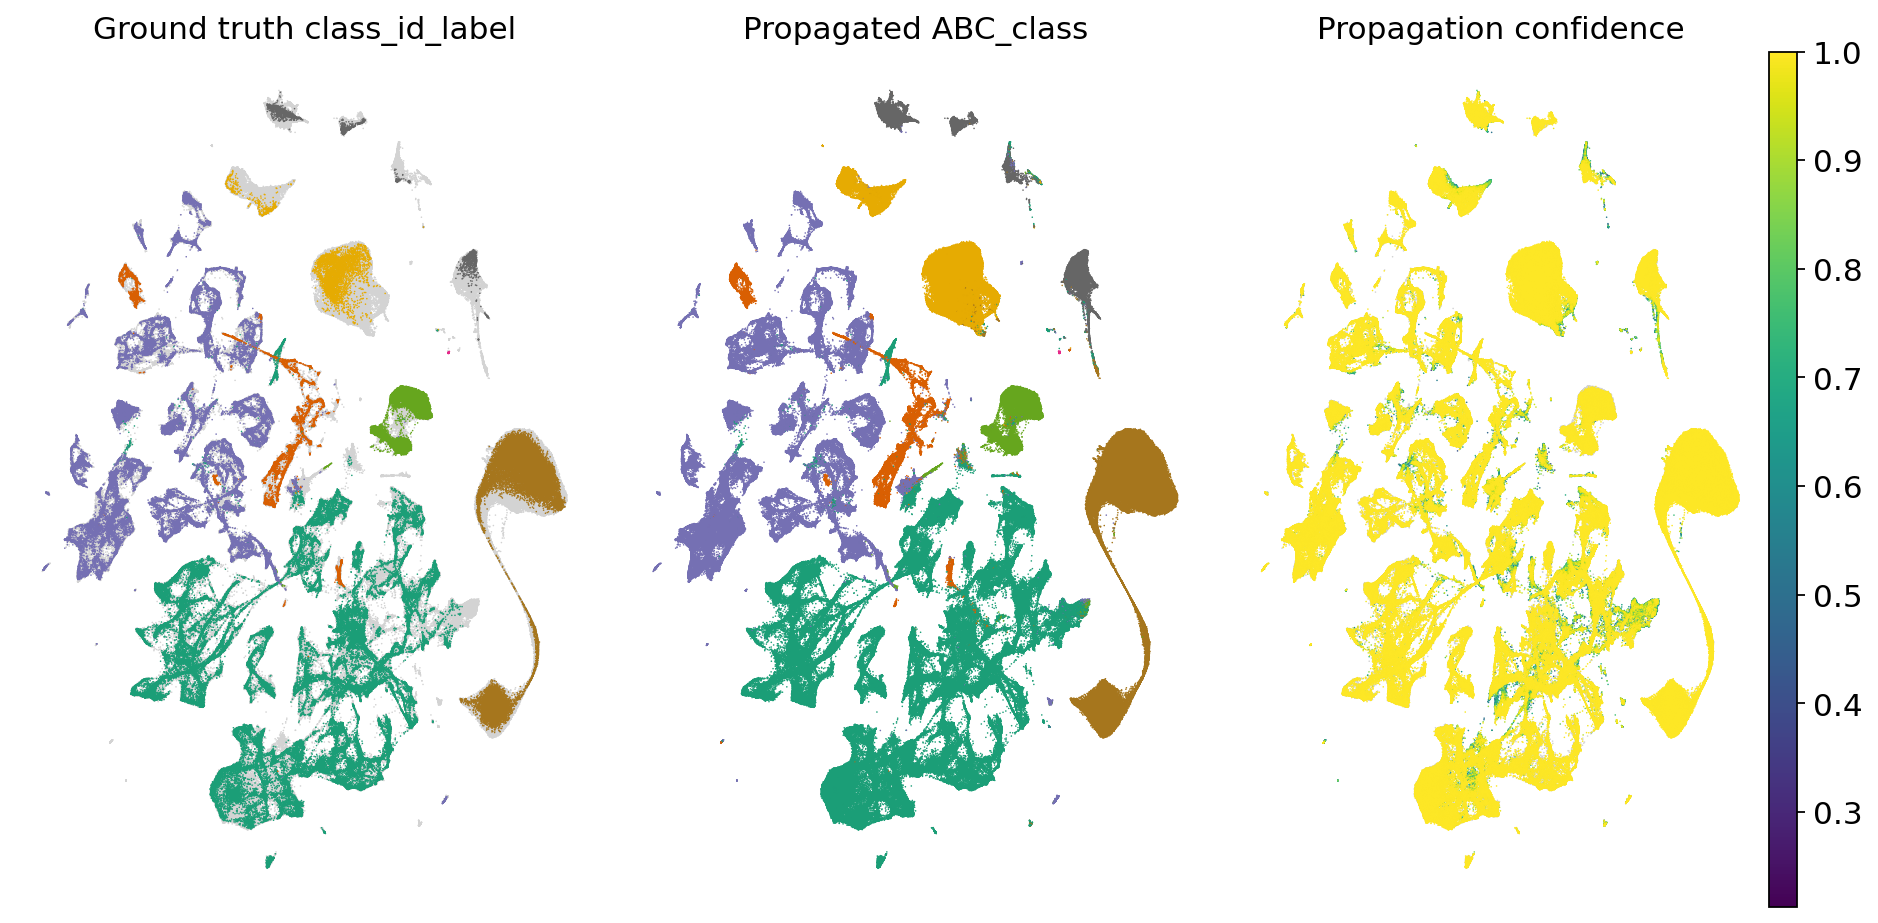

In [66]:
plot_label_propagation_summary(
    adata,
    propagation_label,
    propagation_key,
    save_dir = PLOTS_DIR)


### Let's propagate remaining ABC clustering data

which will be useful to evaluate the clustering

In [67]:

propagation_label = 'supertype_id_label'
propagation_key = 'ABC_supertype'

propagate_labels_within_dataset(adata, propagation_label = propagation_label,
    propagation_key = propagation_key)

In [68]:
propagation_label = 'subclass_id_label'
propagation_key = 'ABC_subclass'

propagate_labels_within_dataset(adata, propagation_label = propagation_label,
    propagation_key = propagation_key)



In [69]:
propagation_label = 'cluster_id_label'
propagation_key = 'ABC_cluster'

propagate_labels_within_dataset(adata, propagation_label = propagation_label,
    propagation_key = propagation_key)

## Save out full data

In [70]:
adata.uns = {k: v for k, v in adata.uns.items() if 'color' not in k}

In [71]:
# Check dtype and convert if it's an integer to avoid rounding errors during normalization
if np.issubdtype(adata.X.dtype, np.integer):
    adata.X = adata.X.astype(np.float32)

adata.write_h5ad(Path(MODELDIR, 'datasets', f'raw_embed_propagated.h5ad'))

## Save out neuronal cells individually

In [72]:
neuronal_mask = adata.obs['major_features_propagated'].isin(['GABA', 'Glut', 'Dopa', 'Sero'])
neuronal_subset = adata[neuronal_mask].copy()

In [73]:
neuronal_subset.write_h5ad(Path(MODELDIR, 'datasets', f'neuronal_raw_embed_propagated.h5ad'))
neuronal_subset

AnnData object with n_obs × n_vars = 630146 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal', 'major_features', 'major_features_propagated', 'major_features_confidence', 'ABC_supertype_propagated', 'ABC_supertype_confidence', 'ABC_subclass_propagated', 'ABC_subclass_confidence', 'ABC_cluster_propagated', 'ABC_cluster_confidence'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'neighbors', 'tsne', 'umap'
    obsm: 'X_

## Save out glial cells individually

In [74]:
glial_subset = adata[~neuronal_mask]

In [75]:
glial_subset.write_h5ad(Path(MODELDIR, 'datasets', f'glial_raw_embed_propagated.h5ad'))
glial_subset

View of AnnData object with n_obs × n_vars = 292309 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal', 'major_features', 'major_features_propagated', 'major_features_confidence', 'ABC_supertype_propagated', 'ABC_supertype_confidence', 'ABC_subclass_propagated', 'ABC_subclass_confidence', 'ABC_cluster_propagated', 'ABC_cluster_confidence'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'neighbors', 'tsne', 'umap'
    o